# 08 · Outlier detection and handling

[Guide](../README.md) | [Previous](07_Dimensionality_Reduction.ipynb) | [Next](09_Class_Imbalance.ipynb)

Inspect unusual values, then compare six responses including two broader removal rules.

## Data: training, validation, competition test
`train.csv` contains known answers; `test.csv` does not.
Split `train.csv`: 16,000 rows for learning and comparisons; 4,000 validation rows for the final check.
Comparisons below stay inside the training part. `random_state` repeats the split;
`stratify` keeps similar goal/miss proportions. `X` means inputs; `y` means answers.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression

plt.style.use("seaborn-v0_8-whitegrid")
pd.set_option("display.precision", 3)

In [2]:
# Change this one folder on Kaggle or Colab (see the guide).
DATA_DIR = "../data"
train = pd.read_csv(f"{DATA_DIR}/train.csv")
test = pd.read_csv(f"{DATA_DIR}/test.csv")
print("Train:", train.shape, "Test:", test.shape)

Train: (20000, 20) Test: (6000, 19)


In [3]:
# Split train.csv: 80% for training, 20% for a separate validation check.
training_data, validation_data = train_test_split(
    train, test_size=0.20, stratify=train["is_scored"], random_state=2026
)
training_data = training_data.reset_index(drop=True)

In [4]:
# IDs identify rows; they do not describe how a penalty was taken.
id_columns = ["id", "kicker_id", "keeper_id", "match_id"]
X = training_data.drop(columns=id_columns + ["is_scored"])
y = training_data["is_scored"]

In [5]:
from sklearn.base import clone
from sklearn.compose import make_column_selector
from sklearn.preprocessing import FunctionTransformer, RobustScaler
from sklearn.ensemble import IsolationForest
from sklearn.feature_selection import SelectFromModel
from sklearn.decomposition import PCA
from imblearn import FunctionSampler
from imblearn.pipeline import Pipeline

## Continue from the earlier lessons

| Earlier decision | Choice used here |
|---|---|
| Missing | Drop incomplete training rows |
| Scaling | Robust scaling |
| Encoding | One-hot |
| Features | All candidate groups |
| Selection | Drop suspected decoys + L1 |
| Reduction | No PCA |

Only the current choice changes. `clone` copies settings, not fitted knowledge; `step__setting` points to one pipeline setting.

**Incomplete training rows:** `any(axis=1)` finds a row with at least one blank; `~` keeps the opposite rows. Filter `y` too so answers stay aligned.

In [6]:
def remove_incomplete_rows(X, y):
    keep = ~X.isna().any(axis=1)
    return X.loc[keep], y[keep]

**Suspected decoys:** test removing jersey color and referee strictness, not every weak-looking input. The same columns are removed at prediction time.

In [7]:
def drop_suspected_decoys(data):
    return data.drop(columns=["jersey_color", "referee_strictness"], errors="ignore")

**Form and technique features:** keep the original inputs and add this group's formulas. `copy()` leaves the original table unchanged; `FunctionTransformer` puts this table-editing function into the pipeline.

In [8]:
def add_relative_features(data):
    data = data.copy()
    data["skill_gap"] = data["player_last5_scored_percent"] - data["goalkeeper_last5_saved_percent"]
    data["foot_advantage"] = data["strong_foot_usage"] - data["weak_foot_usage"]
    data["form_ratio"] = (data["player_last5_scored_percent"] + 1) / (data["goalkeeper_last5_saved_percent"] + 1)
    data["form_interaction"] = data["player_last5_scored_percent"] * data["goalkeeper_last5_saved_percent"] / 100
    data["player_form_squared"] = (data["player_last5_scored_percent"] / 100) ** 2
    data["keeper_form_squared"] = (data["goalkeeper_last5_saved_percent"] / 100) ** 2
    return data

**Match context features:** keep the original inputs and add this group's formulas. `copy()` leaves the original table unchanged; `FunctionTransformer` puts this table-editing function into the pipeline.

In [9]:
def add_pressure_features(data):
    data = data.copy()
    data["late_close_game"] = ((data["minute_taken"] >= 75) & (data["current_score_diff"].abs() <= 1)).astype(int)
    gap = data["player_last5_scored_percent"] - data["goalkeeper_last5_saved_percent"]
    data["skill_under_pressure"] = gap * data["late_close_game"]
    data["after_90_minutes"] = (data["minute_taken"] > 90).astype(int)
    data["trailing"] = (data["current_score_diff"] < 0).astype(int)
    data["tied_game"] = (data["current_score_diff"] == 0).astype(int)
    data["minute_score_interaction"] = data["minute_taken"] * data["current_score_diff"]
    data["crowd_support"] = (data["home_or_away"] == data["crowd_behind_goal"]).astype(int)
    data["late_final"] = ((data["minute_taken"] >= 75) & (data["match_type"] == "Final")).astype(int)
    return data

**Environment features:** keep the original inputs and add this group's formulas. `copy()` leaves the original table unchanged; `FunctionTransformer` puts this table-editing function into the pipeline.

In [10]:
def add_environment_features(data):
    data = data.copy()
    data["poor_pitch"] = (data["pitch_condition"] == "Poor").astype(int)
    data["poor_pitch_late"] = data["poor_pitch"] * (data["minute_taken"] >= 75)
    data["humidity_weak_foot"] = data["weather_humidity"] / 100 * data["weak_foot_usage"]
    data["humidity_squared"] = (data["weather_humidity"] / 100) ** 2
    data["temperature_squared"] = data["temperature"] ** 2
    data["log_capacity"] = np.log1p(data["stadium_capacity"])
    return data

In [11]:
def add_features(data):
    data = add_relative_features(data)
    data = add_pressure_features(data)
    return add_environment_features(data)

In [12]:
def suspicious_rows(data):
    # Screening rules, not proof: unusual time, cold weather, or very large venue.
    return ((data["minute_taken"] > 120) |
            (data["temperature"] < 0) |
            (data["stadium_capacity"] > 110000))

In [13]:
def remove_suspicious(X, y):
    keep = ~suspicious_rows(X)
    return X.loc[keep], y[keep]

**Broader removal:** combine the fixed rules with IQR limits calculated from this training split only.

In [14]:
def remove_broad_outliers(X, y):
    numeric = X.select_dtypes(include="number")
    lower_quartile = numeric.quantile(0.25)
    upper_quartile = numeric.quantile(0.75)
    iqr = upper_quartile - lower_quartile
    outside = (numeric < lower_quartile - 1.5 * iqr) | (numeric > upper_quartile + 1.5 * iqr)
    keep = ~(suspicious_rows(X) | outside.any(axis=1))
    return X.loc[keep], y[keep]

**Isolation Forest:** randomized trees isolate unusual rows; this candidate removes roughly the most unusual 10% of each training split.

In [15]:
def remove_isolation_outliers(X, y):
    numeric = X.select_dtypes(include="number")
    filled = SimpleImputer(strategy="median").fit_transform(numeric)
    detector = IsolationForest(contamination=0.10, random_state=42, n_jobs=2)
    keep = detector.fit_predict(filled) == 1
    return X.loc[keep], y[keep]

In [16]:
def clip_suspicious(data):
    data = data.copy()
    data["minute_taken"] = data["minute_taken"].clip(upper=120)
    data["temperature"] = data["temperature"].clip(lower=0)
    data["stadium_capacity"] = data["stadium_capacity"].clip(upper=110000)
    return data

In [17]:
def add_outlier_flag(data):
    data = data.copy()
    data["unusual_kick"] = suspicious_rows(data).astype(int)
    return data

## Prepare each training split separately
Fill numbers with a training mean or median; fill categories with the most common value (**mode**).
Scaling puts numbers on similar scales. Encoding turns category names into numbers (Lesson 04).
No filling values, rankings, or sampling decisions are learned from validation rows.

In [18]:
numbers = Pipeline([("fill", SimpleImputer(strategy='median')), ("scale", RobustScaler())])
categories = Pipeline([
    ("fill", SimpleImputer(strategy="most_frequent")),
    ("encode", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
])
preprocess = ColumnTransformer([
    ("numbers", numbers, make_column_selector(dtype_include="number")),
    ("categories", categories, make_column_selector(dtype_exclude="number")),
])

**Pipeline:** run steps in order. `passthrough` skips a step. `FunctionSampler` applies a row-changing function only during fitting; every prediction-time row is kept. Balancing also runs only during fitting.

In [19]:
pipeline = Pipeline([
    ("missing_rows", FunctionSampler(func=remove_incomplete_rows, validate=False)),
    ("outlier_rows", "passthrough"),
    ("outlier_values", "passthrough"),
    ("features", FunctionTransformer(add_features)),
    ("decoys", FunctionTransformer(drop_suspected_decoys)),
    ("prepare", preprocess),
    ("selection", SelectFromModel(LogisticRegression(penalty="l1", solver="liblinear", max_iter=1000, random_state=42))),
    ("model", LogisticRegression(solver="liblinear", max_iter=1000, random_state=42)),
])

## Compare on the same three splits
Train on two groups, score the third, and rotate. **F1** balances precision and recall;
**accuracy** counts all correct answers; **ROC-AUC** measures probability ranking.
**F1 spread** shows how much scores change across the three splits.

In [20]:
# Each fold trains on two parts and predicts the third, unseen part.
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

def compare(models, X, y):
    rows = []
    for name, model in models.items():
        scores = cross_validate(model, X, y, cv=cv, scoring=["f1", "accuracy", "roc_auc"])
        rows.append([name, scores["test_f1"].mean(), scores["test_f1"].std(),
                     scores["test_accuracy"].mean(), scores["test_roc_auc"].mean()])
    columns = ["method", "F1", "F1 spread", "accuracy", "ROC-AUC"]
    return pd.DataFrame(rows, columns=columns).sort_values("F1", ascending=False)

## 1. Boxplots: one column at a time
A box contains the middle half of values. **IQR** is that middle-half range.
Points beyond the whiskers are unusual under this rule, not necessarily errors.

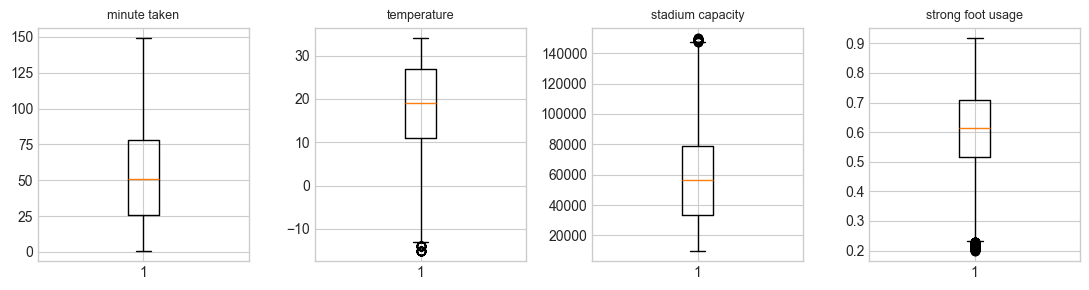

In [21]:
columns = ["minute_taken", "temperature", "stadium_capacity", "strong_foot_usage"]
fig, axes = plt.subplots(1, 4, figsize=(11, 3))
for axis, column in zip(axes, columns):
    axis.boxplot(X[column].dropna())
    axis.set_title(column.replace("_", " "), fontsize=9)
plt.tight_layout()
plt.show()

In [22]:
numeric = X.select_dtypes(include="number")
first_quartile = numeric.quantile(0.25)
third_quartile = numeric.quantile(0.75)
iqr = third_quartile - first_quartile
outside = (numeric < first_quartile - 1.5 * iqr) | (numeric > third_quartile + 1.5 * iqr)
review = pd.DataFrame({"IQR flags": outside.sum(), "minimum": numeric.min(), "maximum": numeric.max()})
review["response"] = "Inspect rare values; keep unless evidence says otherwise"
review.loc[["minute_taken", "temperature", "stadium_capacity"], "response"] = "Compare keep / clip / remove / flag"
display(review)

,IQR flags,minimum,maximum,response
referee_strictness,0,0.000,1.000,Inspect rare values; keep unless evidence says...
stadium_capacity,23,10008.000,149829.000,Compare keep / clip / remove / flag
temperature,42,-15.000,34.000,Compare keep / clip / remove / flag
weather_humidity,0,0.000,99.000,Inspect rare values; keep unless evidence says...
minute_taken,0,1.000,149.000,Compare keep / clip / remove / flag
current_score_diff,0,-3.000,3.000,Inspect rare values; keep unless evidence says...
player_last5_scored_percent,0,0.000,100.000,Inspect rare values; keep unless evidence says...
goalkeeper_last5_saved_percent,0,0.000,100.000,Inspect rare values; keep unless evidence says...
strong_foot_usage,102,0.200,0.917,Inspect rare values; keep unless evidence says...
weak_foot_usage,486,0.112,0.950,Inspect rare values; keep unless evidence says...


In [23]:
limits = {"player_last5_scored_percent": (0, 100), "goalkeeper_last5_saved_percent": (0, 100),
          "weather_humidity": (0, 100), "strong_foot_usage": (0, 1), "weak_foot_usage": (0, 1)}
rows = []
for column, (lower, upper) in limits.items():
    invalid = X[column].notna() & ~X[column].between(lower, upper)
    rows.append([column, invalid.sum()])
display(pd.DataFrame(rows, columns=["physical-range check", "impossible values"]))

,physical-range check,impossible values
0,player_last5_scored_percent,0
1,goalkeeper_last5_saved_percent,0
2,weather_humidity,0
3,strong_foot_usage,0
4,weak_foot_usage,0


## 2. PCA: several measurements together
Scaling prevents capacity from dominating because of its units. PCA compresses measurements into two directions.
The orange screen flags minute > 120, temperature < 0°C, or capacity > 110,000.

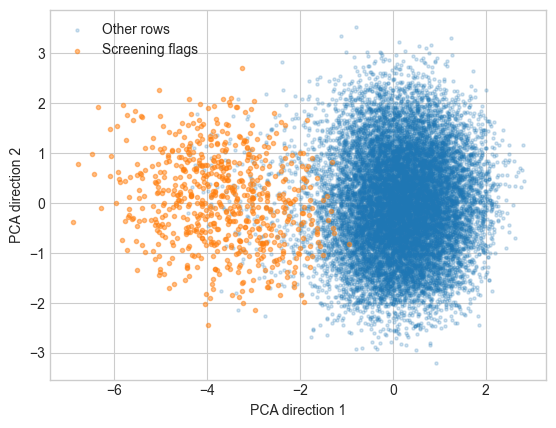

In [24]:
plot_preparation = make_pipeline(SimpleImputer(strategy="median"), StandardScaler())
points = PCA(n_components=2).fit_transform(plot_preparation.fit_transform(numeric))
flagged = suspicious_rows(X)
plt.scatter(points[~flagged, 0], points[~flagged, 1], s=5, alpha=0.2, label="Other rows")
plt.scatter(points[flagged, 0], points[flagged, 1], s=9, alpha=0.5, label="Screening flags")
plt.xlabel("PCA direction 1")
plt.ylabel("PCA direction 2")
plt.legend()
plt.show()

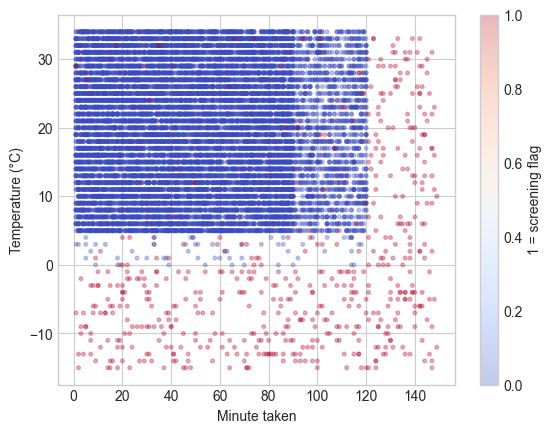

,minute_taken,temperature,stadium_capacity
5,132.0,26.0,115257.0
86,34.0,NaN,113098.0
116,19.0,0.0,132328.0
144,20.0,14.0,118533.0
146,41.0,5.0,142069.0
147,57.0,-14.0,105227.0
154,80.0,-13.0,60535.0
168,NaN,-12.0,111588.0


In [25]:
plt.scatter(X["minute_taken"], X["temperature"], c=flagged, s=7, alpha=0.3, cmap="coolwarm")
plt.xlabel("Minute taken")
plt.ylabel("Temperature (°C)")
plt.colorbar(label="1 = screening flag")
plt.show()
display(X.loc[flagged, ["minute_taken", "temperature", "stadium_capacity"]].head(8))

## 3. Address every type of flag
- Impossible percentages or foot-use proportions: check the source and correct/remove confirmed errors.
- Unusual but possible timing, temperature, or capacity: compare keeping, clipping, removing, or flagging.
- Other IQR flags inside plausible ranges: keep unless inspection provides a reason not to.

A PCA island or boxplot point alone is not proof of an error. The handling rules below are fixed;
learned IQR bounds would instead need fitting inside each training split.

| Strategy | Benefit | Cost |
|---|---|---|
| Keep | Preserve all measurements | Extreme errors could distract the learner |
| Clip | Limit extreme values without losing rows | Replaces possibly real measurements |
| Remove flagged training rows | Avoid learning from suspicious cases | Discards data; flags are not confirmed errors |
| Add a flag | Preserve values and identify unusual cases | Adds a rule-dependent input |
| Remove rules + IQR flags | Remove every fixed-rule flag and any numerical IQR flag | Broader cleanup; can discard valid rare kicks |
| Remove Isolation Forest 10% | Remove the most unusual tenth of training rows | Finds combinations; the 10% assumption can be wrong |

IQR limits and the Isolation Forest are fitted again inside each training split.
A lower retained-row count is not itself a success; compare prediction F1 on all unseen rows.

In [26]:
models = {
    "Keep rows and values": clone(pipeline),
    "Clip flagged values": clone(pipeline).set_params(outlier_values=FunctionTransformer(clip_suspicious)),
    "Remove flagged training rows": clone(pipeline).set_params(outlier_rows=FunctionSampler(func=remove_suspicious, validate=False)),
    "Add a flag": clone(pipeline).set_params(outlier_values=FunctionTransformer(add_outlier_flag)),
    "Remove rules + IQR flags": clone(pipeline).set_params(outlier_rows=FunctionSampler(func=remove_broad_outliers, validate=False)),
    "Remove Isolation Forest 10%": clone(pipeline).set_params(outlier_rows=FunctionSampler(func=remove_isolation_outliers, validate=False)),
}

,method,F1,F1 spread,accuracy,ROC-AUC
3,Add a flag,0.899,0.002,0.910,0.967
0,Keep rows and values,0.880,0.002,0.893,0.960
1,Clip flagged values,0.878,0.003,0.891,0.958
2,Remove flagged training rows,0.875,0.005,0.891,0.948
4,Remove rules + IQR flags,0.875,0.005,0.892,0.934
5,Remove Isolation Forest 10%,0.874,0.004,0.892,0.925


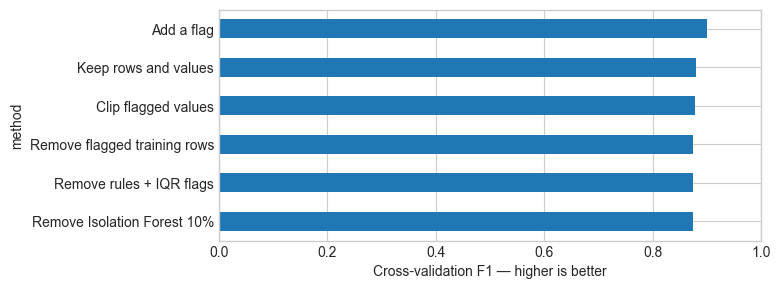

Continue with: Add a flag


In [27]:
results = compare(models, X, y)
display(results.round(4))
results.set_index("method")["F1"].sort_values().plot.barh(figsize=(7, 3))
plt.xlabel("Cross-validation F1 — higher is better")
plt.xlim(0, 1)
plt.show()
print("Continue with:", results.iloc[0]["method"])

## Example: how much training data does each removal rule lose?
Count on the same rows entering this stage. These counts illustrate the rules; they do not choose them.

,screen,rows removed,percent removed
0,Fixed rules,575,4.22
1,Rules + IQR,734,5.38
2,Isolation Forest 10%,1364,10.00


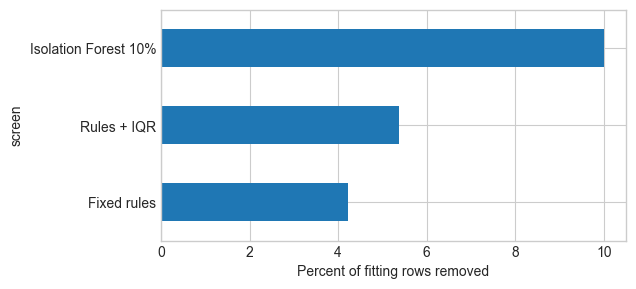

In [28]:
screen_X, screen_y = X.copy(), y.copy()
if "missing_rows" in pipeline.named_steps:
    screen_X, screen_y = pipeline.named_steps["missing_rows"].fit_resample(screen_X, screen_y)
removal_rules = {"Fixed rules": remove_suspicious, "Rules + IQR": remove_broad_outliers,
                 "Isolation Forest 10%": remove_isolation_outliers}
rows = []
for name, rule in removal_rules.items():
    kept_X, kept_y = rule(screen_X, screen_y)
    removed = len(screen_X) - len(kept_X)
    rows.append([name, removed, 100 * removed / len(screen_X)])
removal_counts = pd.DataFrame(rows, columns=["screen", "rows removed", "percent removed"])
display(removal_counts.round(2))
removal_counts.set_index("screen")["percent removed"].plot.barh(figsize=(6, 3))
plt.xlabel("Percent of fitting rows removed")
plt.show()

## Example: keep, clip, remove, or flag the same kicks
The alternatives below show what changes before fitting. Removal applies only to training;
clipping changes measurements; a flag keeps the unusual measurements visible.

In [29]:
sample = X.loc[flagged].head(5)
example = sample[["minute_taken", "temperature", "stadium_capacity"]].copy()
clipped = clip_suspicious(sample)
example["clipped minute"] = clipped["minute_taken"]
example["clipped temperature"] = clipped["temperature"]
example["clipped capacity"] = clipped["stadium_capacity"]
example["unusual_kick flag"] = add_outlier_flag(sample)["unusual_kick"]
example["kept by removal rule"] = ~suspicious_rows(sample)
display(example)

,minute_taken,temperature,stadium_capacity,clipped minute,clipped temperature,clipped capacity,unusual_kick flag,kept by removal rule
5,132.0,26.0,115257.0,120.0,26.0,110000.0,1,False
86,34.0,NaN,113098.0,34.0,NaN,110000.0,1,False
116,19.0,0.0,132328.0,19.0,0.0,110000.0,1,False
144,20.0,14.0,118533.0,20.0,14.0,110000.0,1,False
146,41.0,5.0,142069.0,41.0,5.0,110000.0,1,False


**Why the choice?** All candidates predict every evaluation row. Dropping difficult validation rows
would change the questions and inflate the score. Clipping keeps rows but changes their measurements;
a flag keeps the original information; removal loses training examples.

**Other alternatives:** z-scores use distance from the mean (sensitive to skew); Isolation Forest detects
easy-to-isolate rows; local outlier factor compares neighborhoods. Each detects unusualness, not truth.

## Choice carried into the next lesson

**Outliers: Add a flag.** Keeps the original measurements and tells the model which kicks are unusual instead of deleting them.

This is the best tested choice at this stage, not proof that a small score gap is significant or that every combination has been tried.